# 05 · Comparing Value Iteration, Q-learning and SARSA

**In this notebook**
1. **Test results** (success rate, route length, reward) for all three methods side by side. Every method is tested in exactly the same way.
2. **Training and planning cost**, each in the method's **own units** (sweeps and episodes can *not* be compared directly).
3. How good each policy is against **time**, the only unit all three methods share.
4. Q-learning vs SARSA on the same **episodes** axis (fair, because they use the same units).
5. The policies side by side, with the squares where they differ highlighted.
6. A short discussion of why they differ.

All numbers are loaded from `results/` (worked out in notebooks 02–04).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from frozenlake_rl.config import CONFIG
from frozenlake_rl import env as fl, plotting as plot
from frozenlake_rl.experiments import load_vi, load_td, q_table
from frozenlake_rl.evaluate import greedy_policy, mean_and_ci, seeds_on_time_grid

plot.apply_style()
pd.set_option("display.precision", 3)
MAPS = list(CONFIG["maps"])          # ["4x4", "8x8"]
RERUN = False                        # True = ignore cached CSVs in results/ and recompute

TD = ["Q-learning", "SARSA"]
vi = {m: load_vi(m, rerun=RERUN) for m in MAPS}
td = {(meth, m): load_td(meth, m, rerun=RERUN) for meth in TD for m in MAPS}
envs = {m: fl.make_env(m) for m in MAPS}
optimal = {m: int(vi[m]["summary"]["optimal_steps"].iloc[0]) for m in MAPS}
n_seeds = len(CONFIG["seeds"])

## 1 · Test results (measured the same way for every method)

- **Success rate**: the % of test episodes that reach G.
- **Route length**: the number of steps to reach G, counting **successful episodes only**. Failures have their own column.
- **Return**: the total reward of a test episode.

Value Iteration always gives the same answer, so it has a single result. For Q-learning and SARSA we show the average
over 20 training seeds, with a 95% confidence interval (success rate) or standard deviation (route length, return).
Remember: on non-slippery ice a trained policy always gives the same test result, so all the differences come from the training seeds.

In [2]:
def test_row(test_df):
    per_seed = test_df.groupby("seed").agg(success=("success", "mean"), steps=("steps", "mean"), ret=("return", "mean"))
    ok = per_seed[per_seed["success"] == 1]
    s_mean, _, s_ci = mean_and_ci(100 * per_seed["success"])
    fails = test_df[~test_df["success"]]
    return {"success rate (%)": f"{s_mean:.1f} ± {s_ci:.1f}",
            "path length (steps)": f"{ok['steps'].mean():.2f} ± {ok['steps'].std(ddof=1):.2f}" if len(ok) else "—",
            "return": f"{per_seed['ret'].mean():.3f} ± {per_seed['ret'].std(ddof=1):.3f}",
            "failed test episodes (hole / timeout)": f"{(fails['outcome'] == 'hole').sum()} / {(fails['outcome'] == 'timeout').sum()}",
            "runs": f"{len(per_seed)} seeds"}

rows = []
for m in MAPS:
    t = vi[m]["test"]
    rows.append({"map": m, "method": "Value Iteration",
                 "success rate (%)": f"{100 * t['success'].mean():.1f}",
                 "path length (steps)": f"{t.loc[t['success'], 'steps'].mean():.2f}",
                 "return": f"{t['return'].mean():.3f}",
                 "failed test episodes (hole / timeout)": f"{(t['outcome'] == 'hole').sum()} / {(t['outcome'] == 'timeout').sum()}",
                 "runs": "1 (deterministic)"})
    for meth in TD:
        rows.append({"map": m, "method": meth, **test_row(td[(meth, m)]["test"])})
pd.DataFrame(rows).set_index(["map", "method"])

success rate (%) path length (steps)         return  \
map method                                                                
4x4 Value Iteration            100.0                6.00          0.950   
    Q-learning           100.0 ± 0.0         6.00 ± 0.00  0.950 ± 0.000   
    SARSA                100.0 ± 0.0         6.00 ± 0.00  0.950 ± 0.000   
8x8 Value Iteration            100.0               14.00          0.870   
    Q-learning           100.0 ± 0.0        14.00 ± 0.00  0.870 ± 0.000   
    SARSA                100.0 ± 0.0        14.00 ± 0.00  0.870 ± 0.000   

                    failed test episodes (hole / timeout)               runs  
map method                                                                    
4x4 Value Iteration                                 0 / 0  1 (deterministic)  
    Q-learning                                      0 / 0           20 seeds  
    SARSA                                           0 / 0           20 seeds  
8x8 Value Iteration                                 0 / 0  1 (deterministic)  
    Q-learning                                      0 / 0           20 seeds  
    SARSA                                           0 / 0           20 seeds

## 2 · Training and planning cost (each in its own units)

**A sweep and an episode are not the same amount of work.** A sweep updates every square on the map once, using the
known rules. An episode is one walk from S to the end, updating one Q-value per step. So the numbers below must
**not** be compared between the two groups ("15 sweeps vs 600 episodes" means nothing). Only the time columns use
the same unit.

For Q-learning and SARSA we show the cost of reaching **stable performance** (the shortest route at 5 checkpoints in a row),
as average ± standard deviation over the seeds that got there.

In [3]:
s = {m: vi[m]["summary"].iloc[0] for m in MAPS}
vi_cost = pd.DataFrame({m: {"sweeps": int(s[m]["sweeps"]), "state updates": int(s[m]["state_updates"]),
                            "planning time (ms, median)": round(1000 * s[m]["planning_time_s_median"], 3)}
                        for m in MAPS}).T
display(Markdown("**Value Iteration** (planning, agent never moves)")); display(vi_cost)

def ms(x):
    return f"{x.mean():,.0f} ± {x.std(ddof=1):,.0f}"
rows = []
for m in MAPS:
    for meth in TD:
        st = td[(meth, m)]["stable"]; ok = st[st["reached"]]
        ep = td[(meth, m)]["episodes"]; final = ep[ep["episode"] == ep["episode"].max()]
        rows.append({"map": m, "method": meth,
                     "seeds stable": f"{len(ok)} / {len(st)}",
                     "episodes to stable": ms(ok["episode"]) if len(ok) else "never",
                     "Q-updates to stable": ms(ok["q_updates"]) if len(ok) else "never",
                     "time to stable (ms)": f"{1000 * ok['train_time_s'].mean():.1f} ± {1000 * ok['train_time_s'].std(ddof=1):.1f}" if len(ok) else "never",
                     "full budget: episodes": int(final["episode"].iloc[0]),
                     "full budget: time (ms)": f"{1000 * final['train_time_s'].mean():.1f}"})
display(Markdown("**Q-learning and SARSA** (learning from experience)"))
display(pd.DataFrame(rows).set_index(["map", "method"]))

**Value Iteration** (planning, agent never moves)

,sweeps,state updates,"planning time (ms, median)"
4x4,7.0,77.0,0.105
8x8,15.0,795.0,1.081


**Q-learning and SARSA** (learning from experience)

seeds stable episodes to stable Q-updates to stable  \
map method                                                           
4x4 Q-learning      20 / 20           285 ± 24         1,978 ± 171   
    SARSA           20 / 20           322 ± 34         2,533 ± 283   
8x8 Q-learning      20 / 20           628 ± 55        12,406 ± 895   
    SARSA           20 / 20           538 ± 43      17,442 ± 1,495   

               time to stable (ms)  full budget: episodes  \
map method                                                  
4x4 Q-learning          12.5 ± 1.2                   1000   
    SARSA               16.2 ± 2.1                   1000   
8x8 Q-learning         75.2 ± 14.7                   3000   
    SARSA              94.3 ± 12.4                   3000   

               full budget: time (ms)  
map method                             
4x4 Q-learning                   45.1  
    SARSA                        48.7  
8x8 Q-learning                  327.7  
    SARSA                       371.9

## 3 · Policy quality vs time (the shared unit)

Time means the same thing for all three methods. For Value Iteration we test the policy after every sweep.
For Q-learning and SARSA we use the checkpoints. Testing time is left out for all three.
Each Q-learning or SARSA seed reaches its checkpoints at slightly different times. So at each point on a shared time
scale we take each seed's latest checkpoint, and then average over the seeds.

The time axis uses a **log scale** (each grid line is 10 times the one before), because Value Iteration
finishes about 70–120 times sooner than the learning methods.

*Note:* the exact times depend on this computer and on Python. For example, the learning methods also have to run the
gymnasium game at every step. So only trust the rough size of the numbers, not the exact values.

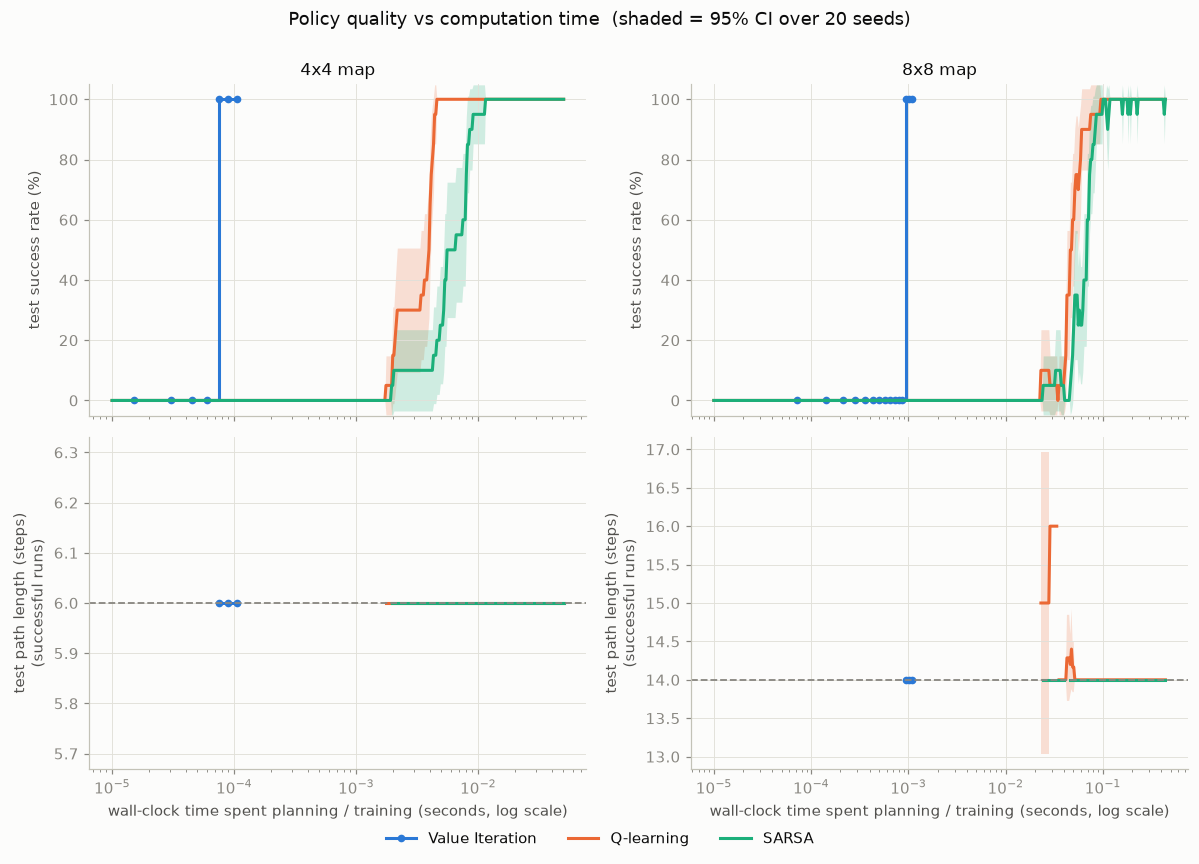

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex="col")
for col, m in enumerate(MAPS):
    sw = vi[m]["sweeps"]
    tmax = max(td[(meth, m)]["checkpoints"]["train_time_s"].max() for meth in TD)
    grid = np.geomspace(1e-5, tmax, 400)
    for row, (column, ylabel) in enumerate([("success_rate", "test success rate (%)"),
                                            ("path_length", "test path length (steps)\n(successful runs)")]):
        ax = axes[row, col]
        ax.step(sw["planning_time_s"], sw[column], where="post", marker="o", ms=4,
                color=plot.COLORS["Value Iteration"], label="Value Iteration")
        for meth in TD:
            plot.band(ax, grid, seeds_on_time_grid(td[(meth, m)]["checkpoints"], column, grid),
                      plot.COLORS[meth], meth)
        ax.set_xscale("log"); ax.set_ylabel(ylabel)
        if row == 0:
            ax.set_ylim(-5, 105); ax.set_title(f"{m} map")
        else:
            ax.axhline(optimal[m], color=plot.INK_MUTED, ls="--", lw=1.2)
            ax.set_xlabel("wall-clock time spent planning / training (seconds, log scale)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Policy quality vs computation time  (shaded = 95% CI over 20 seeds)", y=1.0)
plt.tight_layout(); plot.save_fig(fig, "05_performance_vs_time"); plt.show()

## 4 · Q-learning vs SARSA on the same episodes axis

Q-learning and SARSA use the same units (episodes of experience), so it is fair to compare them on one axis here.

- **Test success rate**: how quickly the frozen greedy policy finds the goal.
- **Training episode reward**: reward collected *while learning*, random moves included (averaged over 25 episodes).
- **Holes fallen into during training** (running total): how risky each agent's behaviour is while it learns.

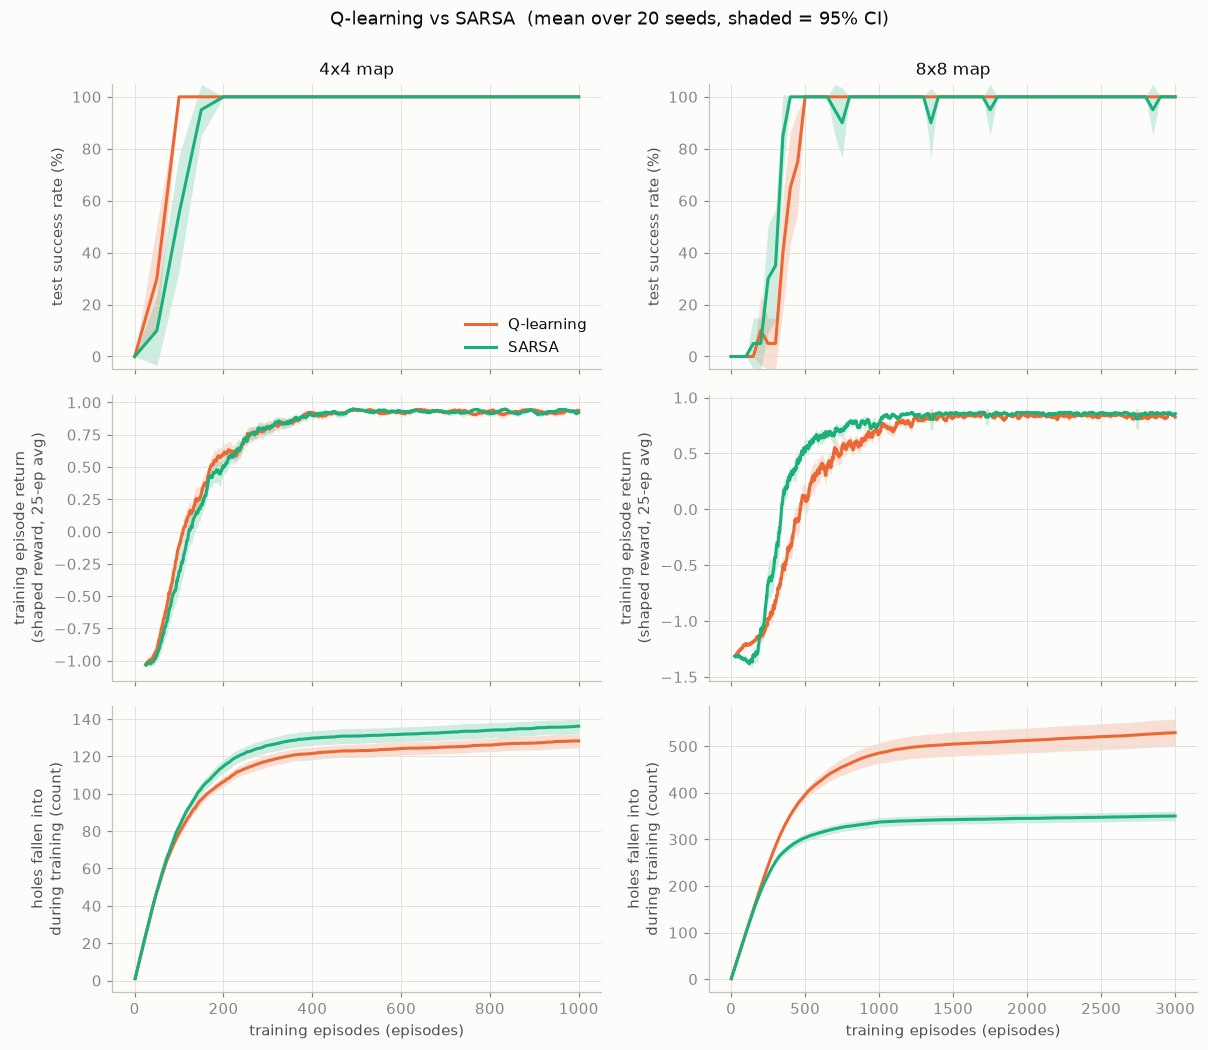

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(11, 9.5), sharex="col")
for col, m in enumerate(MAPS):
    for meth in TD:
        r, c = td[(meth, m)], plot.COLORS[meth]
        x, y = plot.seeds_matrix(r["checkpoints"], "episode", "success_rate")
        plot.band(axes[0, col], x, y, c, meth)
        x, y = plot.seeds_matrix(r["episodes"], "episode", "return")
        plot.band(axes[1, col], x[24:], plot.smooth(y, 25), c, meth)
        ep = r["episodes"].assign(fell=lambda d: d["outcome"] == "hole")
        ep["holes_so_far"] = ep.groupby("seed")["fell"].cumsum()
        x, y = plot.seeds_matrix(ep, "episode", "holes_so_far")
        plot.band(axes[2, col], x, y, c, meth)
    axes[0, col].set_title(f"{m} map"); axes[0, col].set_ylim(-5, 105)
    axes[0, col].set_ylabel("test success rate (%)")
    axes[1, col].set_ylabel("training episode return\n(shaped reward, 25-ep avg)")
    axes[2, col].set_ylabel("holes fallen into\nduring training (count)")
    axes[2, col].set_xlabel("training episodes (episodes)")
axes[0, 0].legend(loc="lower right")
fig.suptitle("Q-learning vs SARSA  (mean over 20 seeds, shaded = 95% CI)", y=1.0)
plt.tight_layout(); plot.save_fig(fig, "05_qlearning_vs_sarsa"); plt.show()

## 5 · Policies side by side

Arrows show each method's greedy action, and the shaded line is its route from S. For the learning methods we show
the run with seed 0. Squares are outlined where the action is **different from Value Iteration's**:

- **yellow outline**: a different action that is **just as good** (FrozenLake often has several shortest routes);
- **red outline**: a different action that is **really worse**, according to Value Iteration's exact Q-values.

We only outline squares the learning agent actually **visited** (a square it never visited would have a small
grey dot; because epsilon starts at 1.0, the agents usually visit every square at least once).

**How to read this:** what matters is the route from S. On that route, the learned policies are always as good as
Value Iteration's: none of the differences on the route are worse, and every route is 6 steps on 4x4 and 14 on 8x8.
Most outlines are in squares **away from the route**. The agent only visited them early on, while moving randomly.
Their Q-values were updated a few times and then left alone, so their arrows are rough guesses.
Value Iteration works out every square exactly, because it doesn't need to visit anything.

4x4 Q-learning: 3 visited squares differ from VI (1 genuinely worse); on its own route: 1 differ, 0 genuinely worse
4x4 SARSA: 2 visited squares differ from VI (0 genuinely worse); on its own route: 1 differ, 0 genuinely worse


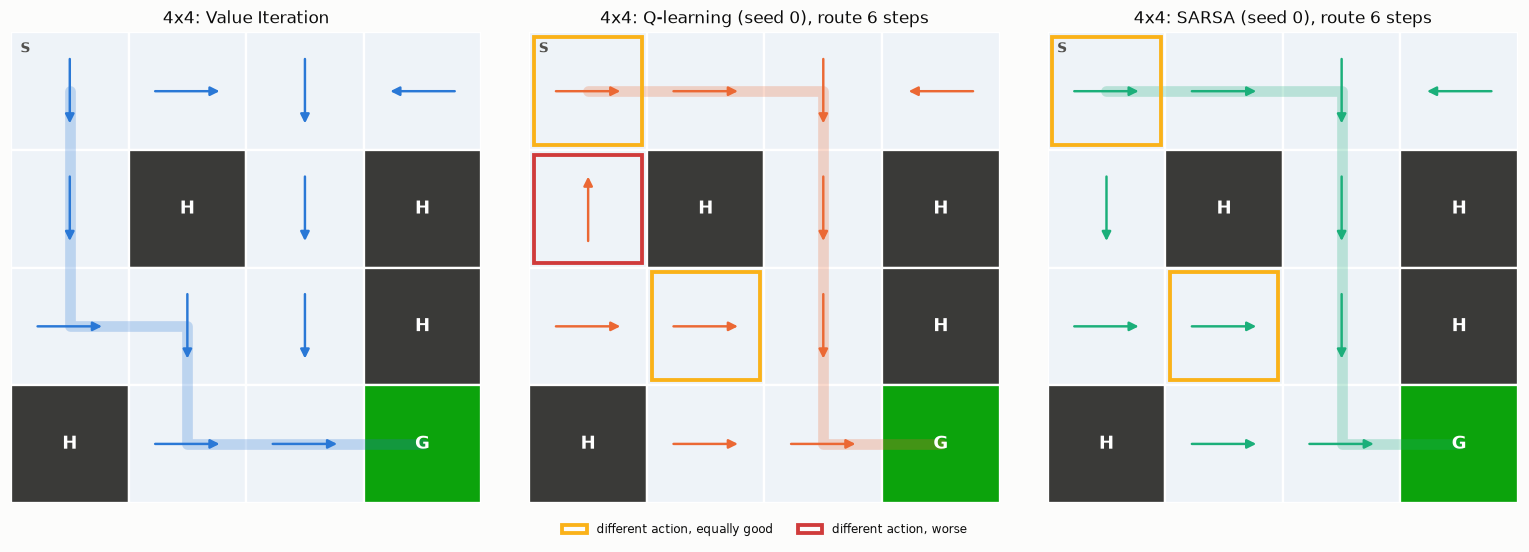

8x8 Q-learning: 22 visited squares differ from VI (11 genuinely worse); on its own route: 6 differ, 0 genuinely worse
8x8 SARSA: 33 visited squares differ from VI (20 genuinely worse); on its own route: 7 differ, 0 genuinely worse


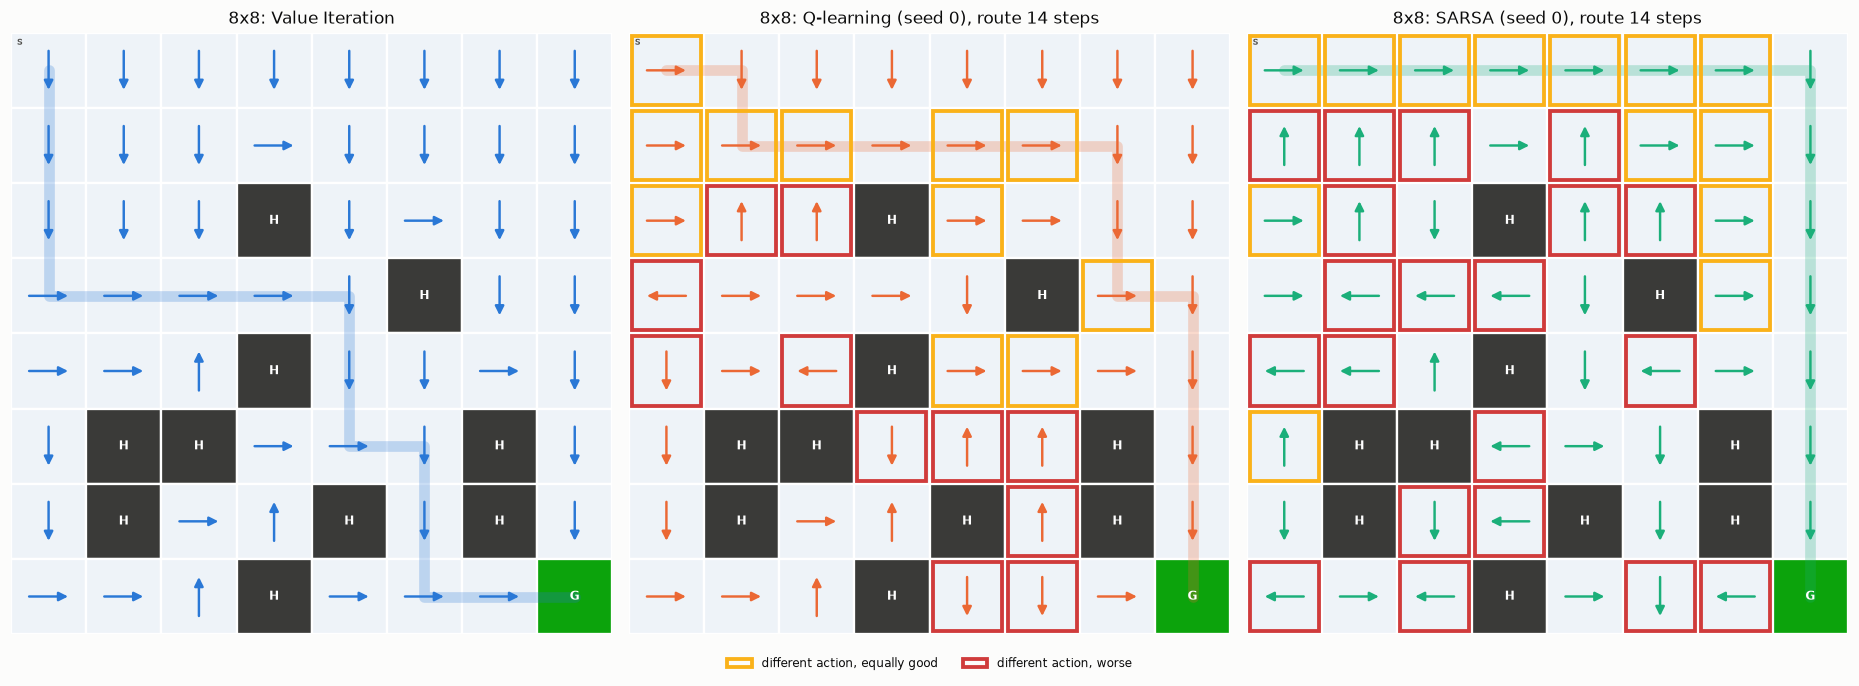

In [6]:
SEED = CONFIG["seeds"][0]
for m in MAPS:
    env = envs[m]; t, shape = fl.tiles(env), fl.grid_shape(env)
    vi_states = vi[m]["states"]
    vi_policy = vi_states["policy"].to_numpy()
    vi_Q = vi_states[["q0", "q1", "q2", "q3"]].to_numpy()
    size = (14, 5) if m == "4x4" else (17, 6.6)
    fig, axes = plt.subplots(1, 3, figsize=size)
    plot.draw_policy(axes[0], t, shape, vi_policy, path=fl.follow_policy(env, vi_policy),
                     color=plot.COLORS["Value Iteration"], title=f"{m}: Value Iteration")
    for ax, meth in zip(axes[1:], TD):
        Q = q_table(td[(meth, m)]["qtables"], SEED)
        policy = greedy_policy(Q)
        visited = [s for s in range(len(t)) if not np.all(Q[s] == CONFIG["td"]["q_init"])]
        diff = plot.policy_differences(policy, vi_policy, vi_Q, t, states=visited)
        path = fl.follow_policy(env, policy)
        plot.draw_policy(ax, t, shape, policy, path=path, color=plot.COLORS[meth], highlight=diff,
                         title=f"{m}: {meth} (seed {SEED}), route {len(path) - 1} steps")
        for s in set(range(len(t))) - set(visited):
            if t[s] not in "GH":
                ax.plot(s % shape[1] + 0.35, s // shape[1] + 0.35, "o", color=plot.INK_MUTED, ms=4)
        n_worse = sum(v == "worse" for v in diff.values())
        on_route = [s for s in path if s in diff]
        n_worse_route = sum(diff[s] == "worse" for s in on_route)
        print(f"{m} {meth}: {len(diff)} visited squares differ from VI ({n_worse} genuinely worse); "
              f"on its own route: {len(on_route)} differ, {n_worse_route} genuinely worse")
    plot.difference_legend(axes[1])
    plt.tight_layout(); plot.save_fig(fig, f"05_policies_{m}"); plt.show()

### How safe are the learned routes?

A route is riskier if it passes close to holes, where one wrong move (for example a random exploring move) ends the episode.
For every seed we count how many squares on its route have a hole **right next to them** (one move away).
We also count how many different routes the 20 seeds ended up with,
and how often each agent fell in a hole in the last 500 training episodes, when it explores the least.

In [7]:
def hole_neighbours(env, path):
    P, t = env.unwrapped.P, fl.tiles(env)
    return sum(any(t[s2] == "H" for a in P[s] for _, s2, _, _ in P[s][a]) for s in path[:-1])

rows = []
for m in MAPS:
    env = envs[m]
    vi_path = fl.follow_policy(env, vi[m]["states"]["policy"].to_numpy())
    rows.append({"map": m, "method": "Value Iteration", "different routes": 1,
                 "route squares next to a hole": f"{hole_neighbours(env, vi_path)}",
                 "fell into a hole, last 500 training episodes (%)": "—"})
    for meth in TD:
        r = td[(meth, m)]
        paths = [fl.follow_policy(env, greedy_policy(q_table(r["qtables"], seed))) for seed in CONFIG["seeds"]]
        nb = np.array([hole_neighbours(env, p) for p in paths])
        ep = r["episodes"]; late = ep[ep["episode"] > ep["episode"].max() - 500]
        fell = late["outcome"] == "hole"
        rows.append({"map": m, "method": meth, "different routes": len({tuple(p) for p in paths}),
                     "route squares next to a hole": f"{nb.mean():.2f} ± {nb.std(ddof=1):.2f}",
                     "fell into a hole, last 500 training episodes (%)": f"{100 * fell.mean():.2f}"})
safety = pd.DataFrame(rows).set_index(["map", "method"])
safety

different routes route squares next to a hole  \
map method                                                           
4x4 Value Iteration                 1                            4   
    Q-learning                      3                  3.75 ± 0.44   
    SARSA                           3                  3.40 ± 0.50   
8x8 Value Iteration                 1                            7   
    Q-learning                     15                  5.85 ± 2.13   
    SARSA                           5                  2.00 ± 0.00   

                    fell into a hole, last 500 training episodes (%)  
map method                                                            
4x4 Value Iteration                                                —  
    Q-learning                                                  1.04  
    SARSA                                                       1.05  
8x8 Value Iteration                                                —  
    Q-learning                                                  1.74  
    SARSA                                                       0.56

## 6 · Discussion: why do the methods differ?

**Value Iteration vs the learning methods.**
Value Iteration is given the whole map and the rules. So it works out the best action everywhere in a few sweeps:
about 0.1 ms on 4x4 and 1 ms on 8x8. Q-learning and SARSA start knowing nothing and have to find the goal by
walking around. On 8x8 the goal is rarely reached by random moves, so they need hundreds of episodes and thousands of
Q-value updates before their policy settles on the shortest route. In return, they **don't need the rules**, which is what
makes them useful when the rules of the world are unknown. Once trained, all three methods reach the goal by a shortest
route, so their *test* results are exactly the same. They differ in how they get there and how much it costs.

**Q-learning vs SARSA.**
The only difference is the target of the update:
- **Q-learning** asks *"what is the best I could do next?"* It assumes it will play perfectly from the next square on,
  even though during training it still makes random moves. So squares next to holes look just as good as any other
  square on a shortest route, and Q-learning is happy to learn routes that pass right next to holes.
- **SARSA** asks *"what will I actually do next?"* Its next move is sometimes random, so standing next to a hole sometimes
  leads to falling in. This **lowers** the value of squares next to holes. So when there are several equally short
  routes, SARSA tends to pick one that stays **away from holes**, and it tends to fall in less while training.

**What our results show.** On the **8x8** map the effect is clear. SARSA's routes pass far fewer squares next to a hole
(2.0 vs 5.9 for Q-learning). It fell in fewer holes while training (0.56% vs 1.74% of the last 500 episodes), and it
collected more reward while learning. Most SARSA runs take the route along the top edge and down the right edge,
away from the holes. On the **4x4** map there is almost no difference (3.4 vs 3.75 squares next to a hole, and the
same fall rate). Every short route on 4x4 passes next to holes, so there is no safer route to choose. In testing, both
methods score exactly the same on both maps (100% success, shortest route).

SARSA's test success rate on 8x8 also drops to 90–95% at a few checkpoints, even after it has become stable. This happens
because a random fall into a hole during training lowers the value of a square on its route, and for a short while
the greedy route breaks. This is the same "my own mistakes count" effect, seen from its downside. Q-learning's target
ignores random mistakes, so once it has learned a route, its policy stays steadier.

Overall the difference is **small** in this setup, for two reasons. First, epsilon drops to 0.01, so late in training
there are hardly any random moves left (and those are the extra risk SARSA plans for). Second, moves are not slippery,
so a careful agent is never punished for walking next to a hole. On a slippery lake, or with more exploring,
the gap between "the best route" (Q-learning) and "the safest route given my own mistakes" (SARSA) could be much bigger.
This is the well-known *cliff-walking* result from reinforcement learning textbooks.

**Limitations.**
Only non-slippery moves; only two small maps; one set of settings (alpha, epsilon schedule), which we did not tune
separately for each method; times depend on the computer; and Q-learning and SARSA policies in rarely visited squares
are unreliable. That doesn't affect reaching the goal from S, but it shows in the arrow maps.

In [8]:
# The same comparison written out with the numbers from this run (updates automatically if results change).
lines = []
for m in MAPS:
    q, s = safety.loc[(m, "Q-learning")], safety.loc[(m, "SARSA")]
    lines.append(f"- **{m}:** route squares next to a hole: Q-learning {q['route squares next to a hole']}, "
                 f"SARSA {s['route squares next to a hole']}. Fell into a hole in the last 500 training episodes: "
                 f"Q-learning {q['fell into a hole, last 500 training episodes (%)']}%, "
                 f"SARSA {s['fell into a hole, last 500 training episodes (%)']}%.")
display(Markdown("**In this run:**\n" + "\n".join(lines)))

**In this run:**
- **4x4:** route squares next to a hole: Q-learning 3.75 ± 0.44, SARSA 3.40 ± 0.50. Fell into a hole in the last 500 training episodes: Q-learning 1.04%, SARSA 1.05%.
- **8x8:** route squares next to a hole: Q-learning 5.85 ± 2.13, SARSA 2.00 ± 0.00. Fell into a hole in the last 500 training episodes: Q-learning 1.74%, SARSA 0.56%.